# Song Recommendation System

**Problem Statement:** Build a hybrid content-based music recommendation engine using 1.16M Spotify tracks (2000–2023). The pipeline combines three learned components:
1. **MLP Genre Classifier** — learns audio feature → genre mappings, extracts second-to-last layer embeddings
2. **Autoencoder** — compresses MLP embeddings into a compact 64-dimensional latent song representation
3. **Hybrid Cosine Similarity** — scores candidates using a weighted combination of latent vectors and raw audio features

**Audio features used:** danceability, energy, loudness, speechiness, acousticness, instrumentalness, liveness, valence, tempo

# Imports

In [1]:
# pandas: loading and manipulating dataframes
import pandas as pd
# numpy: numerical array operations
import numpy as np
# StandardScaler: normalizes audio features to mean=0, std=1
from sklearn.preprocessing import StandardScaler, LabelEncoder
# train_test_split: splits data into training and test sets
from sklearn.model_selection import train_test_split
# MLPClassifier: multi-layer perceptron for genre classification
from sklearn.neural_network import MLPClassifier
# classification_report, confusion_matrix: evaluate MLP genre predictions
from sklearn.metrics import classification_report, confusion_matrix
# cosine_similarity: measures angle-based similarity between song vectors
from sklearn.metrics.pairwise import cosine_similarity
# resample: subsamples data while preserving class proportions
from sklearn.utils import resample
# torch: deep learning framework for building the autoencoder
import torch
# torch.nn: building blocks for neural network layers
import torch.nn as nn
# torch.optim: optimization algorithms for training the autoencoder
import torch.optim as optim
# DataLoader, TensorDataset: handles batching during autoencoder training
from torch.utils.data import DataLoader, TensorDataset
# matplotlib: plotting library for visualizations
import matplotlib.pyplot as plt
# seaborn: higher-level plotting built on matplotlib
import seaborn as sns
# joblib: saves and loads trained sklearn models to disk
import joblib
# gc: garbage collector — forces python to free unused memory
import gc
# os: used to delete temporary memmap files after use
import os
# warnings: suppress non-critical warnings during training
import warnings
warnings.filterwarnings('ignore')

In [2]:
# mapping 82 specific Spotify genres into 12 broad categories
GENRE_MAP = {
    'rock': 'rock', 'alt-rock': 'rock', 'hard-rock': 'rock',
    'punk-rock': 'rock', 'punk': 'rock', 'emo': 'rock',
    'garage': 'rock', 'psych-rock': 'rock', 'rock-n-roll': 'rock',
    'guitar': 'rock',
    'metal': 'metal', 'black-metal': 'metal', 'death-metal': 'metal',
    'heavy-metal': 'metal', 'grindcore': 'metal', 'metalcore': 'metal',
    'industrial': 'metal', 'hardcore': 'metal', 'goth': 'metal',
    'electronic': 'electronic', 'edm': 'electronic', 'house': 'electronic',
    'deep-house': 'electronic', 'chicago-house': 'electronic',
    'detroit-techno': 'electronic', 'techno': 'electronic',
    'minimal-techno': 'electronic', 'trance': 'electronic',
    'drum-and-bass': 'electronic', 'dubstep': 'electronic',
    'electro': 'electronic', 'breakbeat': 'electronic',
    'hardstyle': 'electronic', 'progressive-house': 'electronic',
    'club': 'electronic', 'party': 'electronic', 'dance': 'electronic',
    'hip-hop': 'hip-hop', 'funk': 'hip-hop', 'groove': 'hip-hop',
    'trip-hop': 'hip-hop',
    'pop': 'pop', 'power-pop': 'pop', 'indie-pop': 'pop',
    'k-pop': 'pop', 'cantopop': 'pop', 'pop-film': 'pop',
    'show-tunes': 'pop', 'disco': 'pop',
    'ambient': 'ambient', 'chill': 'ambient', 'new-age': 'ambient',
    'sleep': 'ambient', 'acoustic': 'ambient', 'piano': 'ambient',
    'sad': 'ambient',
    'jazz': 'jazz', 'soul': 'jazz', 'blues': 'jazz', 'gospel': 'jazz',
    'classical': 'classical', 'opera': 'classical',
    'folk': 'folk', 'country': 'folk', 'singer-songwriter': 'folk',
    'songwriter': 'folk',
    'latin': 'latin', 'salsa': 'latin', 'samba': 'latin',
    'forro': 'latin', 'sertanejo': 'latin', 'tango': 'latin',
    'spanish': 'latin', 'dancehall': 'latin', 'dub': 'latin',
    'ska': 'latin',
    'indian': 'world', 'afrobeat': 'world', 'french': 'world',
    'german': 'world', 'swedish': 'world', 'romance': 'world',
    'comedy': 'other',
}

def load_and_preprocess(filepath):
    # load the full spotify dataset from csv
    df = pd.read_csv(filepath)
    # drop the unnamed index column carried over from the csv export
    df = df.drop(columns=['Unnamed: 0'])
    # remove duplicate songs by track ID
    df = df.drop_duplicates(subset='track_id')
    # remove rows with any missing values
    df = df.dropna()
    # preserve original genre label before mapping for use in recommendations
    df['original_genre'] = df['genre']
    # map 82 specific genres down to 12 broad categories
    df['broad_genre'] = df['genre'].map(GENRE_MAP)
    # drop songs whose genre was not in the map
    df = df.dropna(subset=['broad_genre'])
    # define the 9 audio features used throughout the pipeline
    audio_features = [
        'danceability', 'energy', 'loudness', 'speechiness',
        'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo'
    ]
    # normalize audio features to mean=0, std=1 so no single feature dominates
    scaler = StandardScaler()
    # fit scaler on training data and transform in place
    df[audio_features] = scaler.fit_transform(df[audio_features])
    # print dataset stats after preprocessing
    print(f"Dataset shape after preprocessing: {df.shape}")
    print(f"Broad genre distribution:\n{df['broad_genre'].value_counts()}")
    # return dataframe and scaler for reuse in later stages
    return df, scaler

# run preprocessing — make sure spotify_data.csv is in your working directory
df, scaler = load_and_preprocess('spotify_data.csv')

Dataset shape after preprocessing: (1159748, 21)
Broad genre distribution:
broad_genre
electronic    192421
latin         158621
rock          135234
metal         131152
ambient       119024
pop           114190
world          86047
jazz           66220
hip-hop        55490
folk           48677
classical      33338
other          19334
Name: count, dtype: int64


# Stage 1: MLP Genre Classifier

In [3]:
# define the 9 audio features used as MLP input
audio_features = [
    'danceability', 'energy', 'loudness', 'speechiness',
    'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo'
]

# use audio features only — no genre columns as input to avoid leakage
feature_cols = audio_features

# extract feature matrix as numpy array
X = df[feature_cols].values

# encode broad genre strings to integers for MLP output layer
le = LabelEncoder()
# fit encoder on all genre labels and convert to integers
y = le.fit_transform(df['broad_genre'])

# stratified 80/20 split — preserves genre proportions in both sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Training samples: {len(X_train):,}")
print(f"Test samples:     {len(X_test):,}")
print(f"Input dimensions: {X_train.shape[1]}")
print(f"Genres:           {list(le.classes_)}")

Training samples: 927,798
Test samples:     231,950
Input dimensions: 9
Genres:           ['ambient', 'classical', 'electronic', 'folk', 'hip-hop', 'jazz', 'latin', 'metal', 'other', 'pop', 'rock', 'world']


In [4]:
# subsample to 50k — full dataset too slow for CPU MLP training
X_train_small, y_train_small = resample(
    X_train, y_train, n_samples=50000, random_state=42, stratify=y_train
)

# single hidden layer of 256 neurons — sufficient capacity without slow training
mlp = MLPClassifier(
    hidden_layer_sizes=(256,),
    activation='relu',
    learning_rate_init=0.001,
    max_iter=200,
    early_stopping=True,
    n_iter_no_change=10,
    random_state=42,
    verbose=True
)

# train MLP on subsampled data
mlp.fit(X_train_small, y_train_small)
print("\nMLP training complete.")

Iteration 1, loss = 1.88135332
Validation score: 0.395000
Iteration 2, loss = 1.75906569
Validation score: 0.398600
Iteration 3, loss = 1.74400352
Validation score: 0.400000
Iteration 4, loss = 1.73483761
Validation score: 0.401200
Iteration 5, loss = 1.72893585
Validation score: 0.399200
Iteration 6, loss = 1.72349474
Validation score: 0.404000
Iteration 7, loss = 1.71863026
Validation score: 0.403000
Iteration 8, loss = 1.71545478
Validation score: 0.405200
Iteration 9, loss = 1.71142122
Validation score: 0.406400
Iteration 10, loss = 1.70892508
Validation score: 0.403800
Iteration 11, loss = 1.70628821
Validation score: 0.400600
Iteration 12, loss = 1.70373927
Validation score: 0.407600
Iteration 13, loss = 1.70112055
Validation score: 0.406400
Iteration 14, loss = 1.69866884
Validation score: 0.406400
Iteration 15, loss = 1.69621699
Validation score: 0.410200
Iteration 16, loss = 1.69378327
Validation score: 0.405400
Iteration 17, loss = 1.69251294
Validation score: 0.411400
Iterat

              precision    recall  f1-score   support

     ambient       0.50      0.51      0.51     23805
   classical       0.42      0.34      0.38      6668
  electronic       0.53      0.72      0.61     38484
        folk       0.24      0.06      0.10      9735
     hip-hop       0.29      0.10      0.15     11098
        jazz       0.22      0.05      0.08     13244
       latin       0.41      0.56      0.47     31724
       metal       0.57      0.61      0.59     26231
       other       0.89      0.77      0.82      3867
         pop       0.24      0.31      0.27     22838
        rock       0.30      0.35      0.33     27047
       world       0.22      0.08      0.12     17209

    accuracy                           0.43    231950
   macro avg       0.40      0.37      0.37    231950
weighted avg       0.40      0.43      0.40    231950



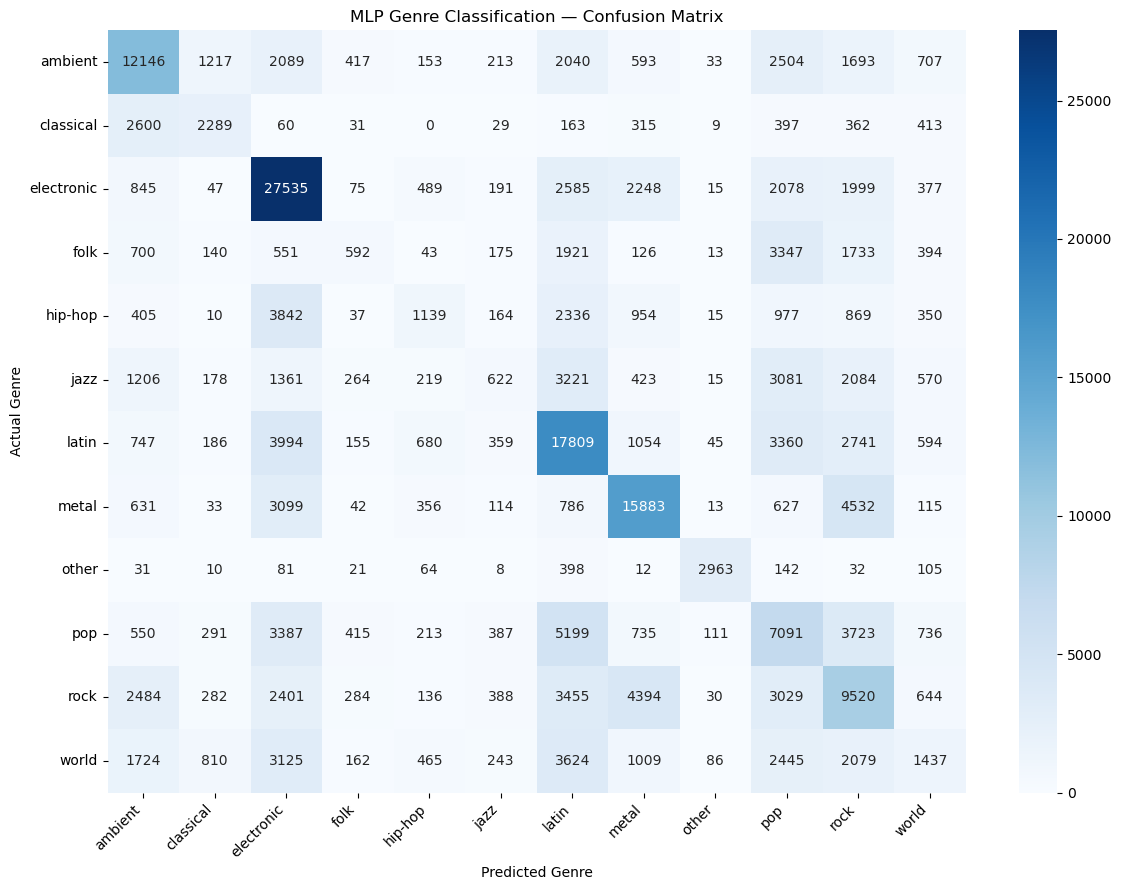

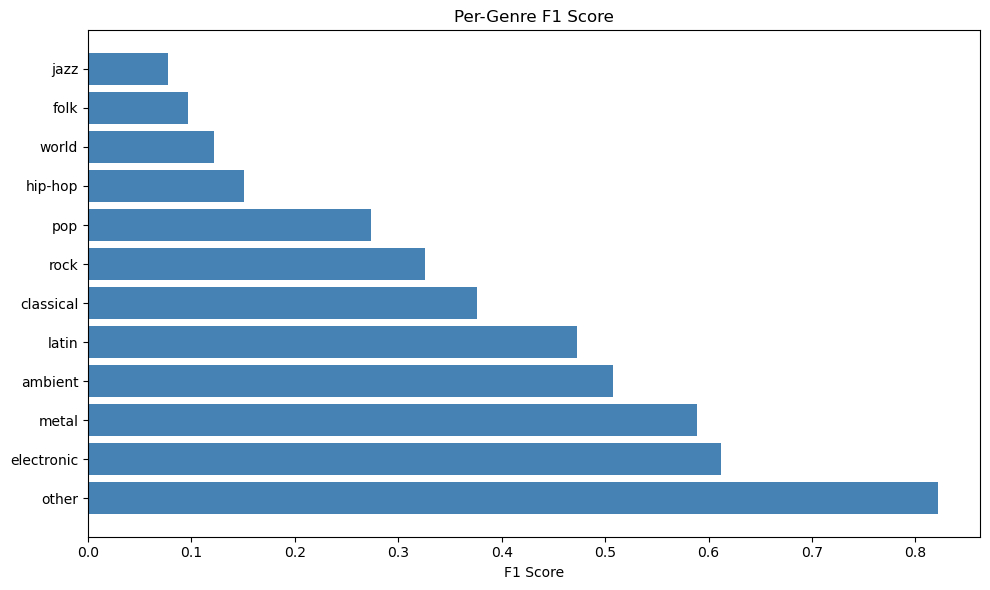

In [5]:
# predict genres on held-out test set
y_pred = mlp.predict(X_test)

# print per-genre precision, recall, and f1 score
print(classification_report(y_test, y_pred, target_names=le.classes_, zero_division=0))

# plot confusion matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(12, 9))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=le.classes_, yticklabels=le.classes_)
plt.xlabel('Predicted Genre')
plt.ylabel('Actual Genre')
plt.title('MLP Genre Classification — Confusion Matrix')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

# build classification report as dict for f1 bar chart
report = classification_report(
    y_test, y_pred, target_names=le.classes_, output_dict=True, zero_division=0
)
# extract f1 score for each genre
f1_scores = {genre: report[genre]['f1-score'] for genre in le.classes_}
# sort descending so best-performing genres appear first
f1_sorted = dict(sorted(f1_scores.items(), key=lambda x: x[1], reverse=True))

# plot per-genre f1 scores as horizontal bar chart
plt.figure(figsize=(10, 6))
plt.barh(list(f1_sorted.keys()), list(f1_sorted.values()), color='steelblue')
plt.xlabel('F1 Score')
plt.title('Per-Genre F1 Score')
plt.tight_layout()
plt.show()

In [6]:
# save trained MLP to disk so we never have to retrain from scratch
joblib.dump(mlp, 'mlp_model.pkl')
# save label encoder to preserve genre-to-integer mappings
joblib.dump(le, 'label_encoder.pkl')
# save scaler for consistent feature normalization on new songs
joblib.dump(scaler, 'scaler.pkl')

print("MLP, label encoder, and scaler saved.")

MLP, label encoder, and scaler saved.


In [7]:
# load all saved components — run this cell instead of retraining after first run
mlp = joblib.load('mlp_model.pkl')
# load label encoder to decode integer predictions back to genre names
le = joblib.load('label_encoder.pkl')
# load scaler for consistent audio feature normalization
scaler = joblib.load('scaler.pkl')

print("MLP, label encoder, and scaler loaded.")

MLP, label encoder, and scaler loaded.


In [8]:
def extract_embeddings(mlp, X):
    # start with the full feature matrix as input to the first layer
    layer_input = X
    # iterate through all layers except the final output layer
    for i, (weights, biases) in enumerate(zip(mlp.coefs_[:-1], mlp.intercepts_[:-1])):
        # apply linear transformation: multiply input by weights and add bias
        layer_input = layer_input @ weights + biases
        # apply relu activation — sets any negative values to zero
        layer_input = np.maximum(0, layer_input)
    # layer_input is now the second-to-last layer output — the 256-dim song embedding
    return layer_input

# define the same audio features used during MLP training
audio_features = [
    'danceability', 'energy', 'loudness', 'speechiness',
    'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo'
]

# extract audio feature matrix for every song in the full dataset
X_full = df[audio_features].values

# extract 256-dimensional embeddings for all 1.15M songs
embeddings = extract_embeddings(mlp, X_full)

print(f"Embedding shape: {embeddings.shape}")

Embedding shape: (1159748, 256)


In [9]:
# save embeddings to disk so we never have to recompute them
np.save('embeddings.npy', embeddings)
print("Embeddings saved.")

Embeddings saved.


In [10]:
# load pre-computed embeddings — run this instead of recomputing
embeddings = np.load('embeddings.npy')
print("Embeddings loaded:", embeddings.shape)

Embeddings loaded: (1159748, 256)


# Stage 2: Autoencoder

In [11]:
# define the autoencoder architecture using pytorch
class SongAutoencoder(nn.Module):
    def __init__(self, input_dim, latent_dim):
        # initialize the parent pytorch module class
        super(SongAutoencoder, self).__init__()

        # encoder: compresses the 256-dim MLP embedding down to latent_dim
        self.encoder = nn.Sequential(
            nn.Linear(input_dim, 128),
            nn.ReLU(),
            nn.BatchNorm1d(128),
            nn.Linear(128, latent_dim),
            nn.ReLU()
        )

        # decoder: reconstructs the original 256-dim embedding from latent_dim
        # only used during training — discarded after the autoencoder is trained
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 128),
            nn.ReLU(),
            nn.BatchNorm1d(128),
            nn.Linear(128, input_dim),
        )

    def forward(self, x):
        # pass input through encoder to get compressed latent representation
        latent = self.encoder(x)
        # pass latent through decoder to reconstruct original embedding
        reconstructed = self.decoder(latent)
        return reconstructed, latent

# input dimension matches the MLP second-to-last layer output size
input_dim = embeddings.shape[1]
# latent dimension — final compressed representation size
latent_dim = 64

# instantiate the autoencoder
autoencoder = SongAutoencoder(input_dim=input_dim, latent_dim=latent_dim)
print(autoencoder)
print(f"\nInput dim: {input_dim} → Latent dim: {latent_dim}")

SongAutoencoder(
  (encoder): Sequential(
    (0): Linear(in_features=256, out_features=128, bias=True)
    (1): ReLU()
    (2): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (3): Linear(in_features=128, out_features=64, bias=True)
    (4): ReLU()
  )
  (decoder): Sequential(
    (0): Linear(in_features=64, out_features=128, bias=True)
    (1): ReLU()
    (2): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (3): Linear(in_features=128, out_features=256, bias=True)
  )
)

Input dim: 256 → Latent dim: 64


Epoch 1/10 — Loss: 0.119996
Epoch 2/10 — Loss: 0.026056
Epoch 3/10 — Loss: 0.012225
Epoch 4/10 — Loss: 0.009172
Epoch 5/10 — Loss: 0.007569
Epoch 6/10 — Loss: 0.006562
Epoch 7/10 — Loss: 0.005773
Epoch 8/10 — Loss: 0.005239
Epoch 9/10 — Loss: 0.004774
Epoch 10/10 — Loss: 0.004385


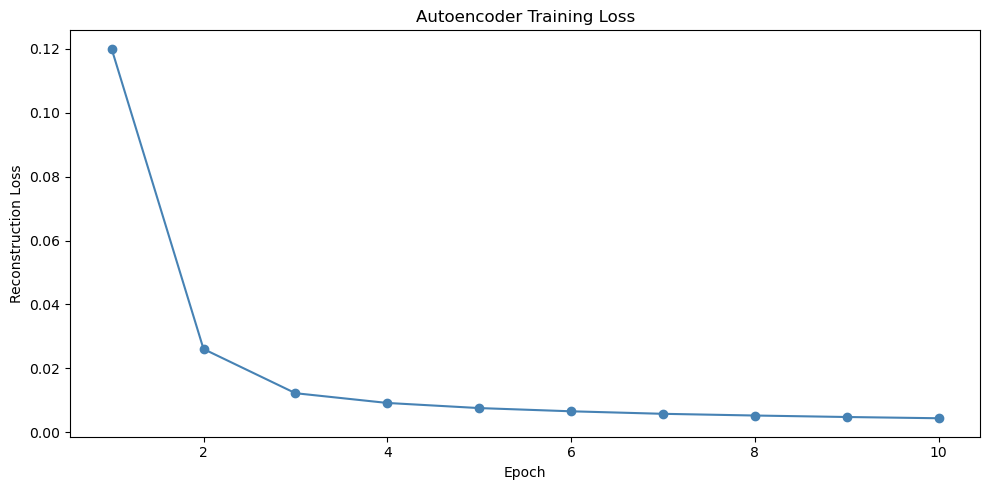

Autoencoder training complete.


In [12]:
# subsample 100k embeddings — full 1.15M too slow per epoch
sample_idx = np.random.choice(len(embeddings), size=100000, replace=False)
embeddings_sample = embeddings[sample_idx]

# convert subsampled embeddings to a pytorch tensor
embeddings_tensor = torch.FloatTensor(embeddings_sample)
# wrap tensor in a dataset object for use with DataLoader
dataset = TensorDataset(embeddings_tensor)
# larger batch size — fewer updates per epoch, much faster training
dataloader = DataLoader(dataset, batch_size=2048, shuffle=True)

# mean squared error loss — measures how well the decoder reconstructs the input
criterion = nn.MSELoss()
# adam optimizer
optimizer = optim.Adam(autoencoder.parameters(), lr=0.001)

# number of training epochs
num_epochs = 10

# track average loss per epoch for plotting
epoch_losses = []

for epoch in range(num_epochs):
    total_loss = 0
    for batch in dataloader:
        x = batch[0]
        optimizer.zero_grad()
        reconstructed, latent = autoencoder(x)
        loss = criterion(reconstructed, x)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
    avg_loss = total_loss / len(dataloader)
    epoch_losses.append(avg_loss)
    print(f"Epoch {epoch+1}/{num_epochs} — Loss: {avg_loss:.6f}")

# plot reconstruction loss to confirm training converged
plt.figure(figsize=(10, 5))
plt.plot(range(1, num_epochs+1), epoch_losses, marker='o', color='steelblue')
plt.xlabel('Epoch')
plt.ylabel('Reconstruction Loss')
plt.title('Autoencoder Training Loss')
plt.tight_layout()
plt.show()

print("Autoencoder training complete.")

In [13]:
# save trained autoencoder weights to disk
torch.save(autoencoder.state_dict(), 'autoencoder.pth')
print("Autoencoder saved.")

Autoencoder saved.


In [14]:
# instantiate a fresh autoencoder with the same architecture
autoencoder = SongAutoencoder(input_dim=input_dim, latent_dim=latent_dim)
# load the saved weights into the fresh instance
autoencoder.load_state_dict(torch.load('autoencoder.pth'))
# set to evaluation mode
autoencoder.eval()
print("Autoencoder loaded.")

Autoencoder loaded.


# Stage 3: Latent Vectors + Recommendations

In [15]:
# set autoencoder to evaluation mode before extracting latent vectors
autoencoder.eval()

# disable gradient computation since we are only doing inference
with torch.no_grad():
    # convert full embeddings array to a pytorch tensor
    full_tensor = torch.FloatTensor(embeddings)
    # pass through encoder only — discard decoder output
    latent_vectors = autoencoder.encoder(full_tensor).numpy()

print(f"Latent vectors shape: {latent_vectors.shape}")

# save latent vectors to disk so we never have to recompute
np.save('latent_vectors.npy', latent_vectors)
print("Latent vectors saved.")

Latent vectors shape: (1159748, 64)
Latent vectors saved.


In [16]:
# load pre-computed latent vectors from disk
latent_vectors = np.load('latent_vectors.npy')
print("Latent vectors loaded:", latent_vectors.shape)

Latent vectors loaded: (1159748, 64)


In [17]:
# audio feature list used for cosine similarity scoring
audio_features = [
    'danceability', 'energy', 'loudness', 'speechiness',
    'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo'
]

# extract scaled audio feature matrix for all songs
audio_matrix = df[audio_features].values

# reset dataframe index so positional indexing aligns with matrix rows
df = df.reset_index(drop=True)

def recommend_songs(song_name, artist_name=None, n=10, alpha=0.65, beta=0.35):
    # search for the song by name, optionally filtered by artist
    if artist_name:
        matches = df[
            (df['track_name'].str.lower() == song_name.lower()) &
            (df['artist_name'].str.lower() == artist_name.lower())
        ]
    else:
        matches = df[df['track_name'].str.lower() == song_name.lower()]

    if len(matches) == 0:
        print(f"Song '{song_name}' not found in database.")
        return None

    # use the first match if multiple versions exist
    song_idx = matches.index[0]
    song_row = df.iloc[song_idx]
    print(f"Finding recommendations for: {song_row['track_name']} by {song_row['artist_name']}")
    print(f"Original genre: {song_row['original_genre']} | Broad genre: {song_row['broad_genre']}\n")

    # extract the input song's latent and audio vectors
    song_latent = latent_vectors[song_idx].reshape(1, -1)
    song_audio = audio_matrix[song_idx].reshape(1, -1)

    # filter candidates to only songs in the same original genre
    same_genre_mask = df['original_genre'] == song_row['original_genre']
    same_genre_indices = df[same_genre_mask].index.tolist()

    # extract latent and audio vectors for same-genre candidates only
    latent_filtered = latent_vectors[same_genre_indices]
    audio_filtered = audio_matrix[same_genre_indices]

    # compute cosine similarity for latent vectors and raw audio features
    latent_sim = cosine_similarity(song_latent, latent_filtered)[0]
    audio_sim = cosine_similarity(song_audio, audio_filtered)[0]

    # combine with weighted sum
    combined_score = alpha * latent_sim + beta * audio_sim

    # sort candidates by combined score descending
    sorted_positions = np.argsort(combined_score)[::-1]

    # collect top-n recommendations, skipping the input song itself
    recommendations = []
    for pos in sorted_positions:
        idx = same_genre_indices[pos]
        if idx == song_idx:
            continue
        recommendations.append({
            'track_name':     df.iloc[idx]['track_name'],
            'artist_name':    df.iloc[idx]['artist_name'],
            'original_genre': df.iloc[idx]['original_genre'],
            'broad_genre':    df.iloc[idx]['broad_genre'],
            'score':          round(combined_score[pos], 4)
        })
        if len(recommendations) == n:
            break

    return pd.DataFrame(recommendations)

In [20]:
def get_recommendations_from_input():
    song_name = input("Enter song name: ").strip()
    if not song_name:
        print("Invalid input: song name cannot be empty.")
        return
    artist_name = input("Enter artist name (press Enter to skip): ").strip()
    if artist_name == '':
        artist_name = None
    n_input = input("How many recommendations? (default 10): ").strip()
    n = int(n_input) if n_input.isdigit() and int(n_input) > 0 else 10
    song_matches = df[df['track_name'].str.lower() == song_name.lower()]
    if len(song_matches) == 0:
        print(f"Song '{song_name}' not found in database.")
        return
    if artist_name:
        artist_matches = song_matches[
            song_matches['artist_name'].str.lower() == artist_name.lower()
        ]
        if len(artist_matches) == 0:
            print(f"'{song_name}' by '{artist_name}' not found. Found these versions instead:")
            print(song_matches[['track_name', 'artist_name', 'original_genre']].to_string())
            return
    results = recommend_songs(song_name, artist_name, n=n)
    if results is not None:
        print("\nTop Recommendations:")
        print(results.to_string())

get_recommendations_from_input()

Enter song name:  Baby
Enter artist name (press Enter to skip):  Justin Bieber
How many recommendations? (default 10):  


Finding recommendations for: Baby by Justin Bieber
Original genre: pop | Broad genre: pop


Top Recommendations:
                       track_name    artist_name original_genre broad_genre   score
0                   No Other Love   Common Kings            pop         pop  0.9625
1                  American Woman  Lenny Kravitz            pop         pop  0.9293
2                          Fading        Rihanna            pop         pop  0.9225
3  You Don't Love Me (No, No, No)        Rihanna            pop         pop  0.9216
4                       Endlessly     Kali Uchis            pop         pop  0.9216
5                          Hey DJ           CNCO            pop         pop  0.9183
6  Green Light (feat. André 3000)    John Legend            pop         pop  0.9183
7                Diamonds - Remix        Rihanna            pop         pop  0.9177
8               Gimme What I Want    Miley Cyrus            pop         pop  0.9108
9                        Dear God       Confett

# Evaluation

Train pool: 927,798 | Test pool: 231,950
Evaluating 200 input songs, top-10 recs each...

BASELINE EVALUATION RESULTS
Songs evaluated:          200
Recommendations per song: 10

Mean original_genre match rate:  0.3830  (model)
Mean random match rate:          0.1652  (chance)
Mean lift:                       0.2178  <- model vs random
Mean similarity score:           0.9786

Per-genre lift:
             match_rate  random_match_rate    lift
query_genre                                       
jazz             0.6583             0.2524  0.4059
ambient          0.4625             0.1468  0.3157
latin            0.3909             0.1110  0.2799
classical        0.7625             0.5000  0.2625
world            0.4167             0.1570  0.2597
electronic       0.2576             0.0687  0.1889
rock             0.3045             0.1163  0.1882
hip-hop          0.4091             0.2380  0.1711
pop              0.3000             0.1313  0.1687
metal            0.2381             0.1256  0

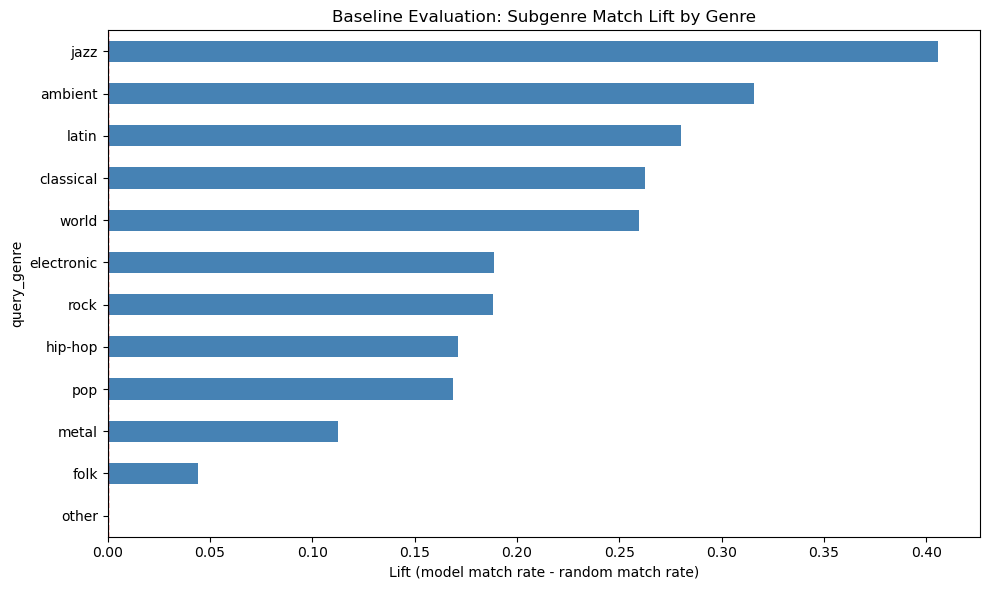

In [21]:
def evaluate_baseline(df, latent_vectors, audio_matrix,
                      n_query_songs=200, n=10, alpha=0.65, beta=0.35,
                      test_size=0.2, random_state=42):
    """
    Evaluates whether the recommender captures subgenre structure better than chance.
    For each input song in the test set, checks what fraction of the top-N recommendations
    share the same original genre. Compares against random chance within the same broad genre.
    Positive lift = model does better than random.
    """
    all_indices = df.index.tolist()
    train_indices, test_indices = train_test_split(
        all_indices, test_size=test_size, random_state=random_state,
        stratify=df['broad_genre']
    )
    train_mask = np.isin(df.index.values, train_indices)

    print(f"Train pool: {len(train_indices):,} | Test pool: {len(test_indices):,}")

    query_sample = df.loc[test_indices].sample(n=n_query_songs, random_state=random_state)
    print(f"Evaluating {n_query_songs} input songs, top-{n} recs each...\n")

    results = []

    for song_idx, song_row in query_sample.iterrows():
        query_original = song_row['original_genre']
        query_broad    = song_row['broad_genre']

        broad_mask = (df['broad_genre'] == query_broad).values
        cands = df.index[broad_mask & train_mask].tolist()

        if len(cands) < n:
            continue

        cand_genres = df.loc[cands, 'original_genre']
        random_match_rate = (cand_genres == query_original).mean()

        q_lat = latent_vectors[song_idx].reshape(1, -1)
        q_aud = audio_matrix[song_idx].reshape(1, -1)

        combined = (
            alpha * cosine_similarity(q_lat, latent_vectors[cands])[0] +
            beta  * cosine_similarity(q_aud, audio_matrix[cands])[0]
        )

        top_pos = np.argsort(combined)[::-1]
        top_pos = [p for p in top_pos if cands[p] != song_idx][:n]
        top_idx = [cands[p] for p in top_pos]
        top_scores = combined[top_pos]

        match_rate = (df.loc[top_idx, 'original_genre'] == query_original).mean()

        results.append({
            'query_song':         song_row['track_name'],
            'query_artist':       song_row['artist_name'],
            'query_genre':        query_broad,
            'original_genre':     query_original,
            'match_rate':         round(match_rate, 4),
            'random_match_rate':  round(random_match_rate, 4),
            'lift':               round(match_rate - random_match_rate, 4),
            'mean_score':         round(float(np.mean(top_scores)), 4),
        })

    results_df = pd.DataFrame(results)

    print("=" * 55)
    print("BASELINE EVALUATION RESULTS")
    print("=" * 55)
    print(f"Songs evaluated:          {len(results_df)}")
    print(f"Recommendations per song: {n}")
    print()
    print(f"Mean original_genre match rate:  {results_df['match_rate'].mean():.4f}  (model)")
    print(f"Mean random match rate:          {results_df['random_match_rate'].mean():.4f}  (chance)")
    print(f"Mean lift:                       {results_df['lift'].mean():.4f}  <- model vs random")
    print(f"Mean similarity score:           {results_df['mean_score'].mean():.4f}")
    print()
    print("Per-genre lift:")
    genre_summary = (
        results_df.groupby('query_genre')[['match_rate', 'random_match_rate', 'lift']]
        .mean().sort_values('lift', ascending=False).round(4)
    )
    print(genre_summary.to_string())
    print("=" * 55)

    plt.figure(figsize=(10, 6))
    genre_summary['lift'].sort_values().plot(kind='barh', color='steelblue')
    plt.axvline(0, color='red', linestyle='--', linewidth=1)
    plt.xlabel('Lift (model match rate - random match rate)')
    plt.title('Baseline Evaluation: Subgenre Match Lift by Genre')
    plt.tight_layout()
    plt.show()

    return results_df

eval_results = evaluate_baseline(df, latent_vectors, audio_matrix, n_query_songs=200, n=10)

Set A: 463,900 | Set B: 463,899 | Test: 231,949
Sets A and B have zero overlap — confirmed by design.

Training Model A
Iteration 1, loss = 1.87445858
Validation score: 0.396600
Iteration 2, loss = 1.75139280
Validation score: 0.397400
Iteration 3, loss = 1.73566259
Validation score: 0.398000
Iteration 4, loss = 1.72698277
Validation score: 0.404000
Iteration 5, loss = 1.72122141
Validation score: 0.406600
Iteration 6, loss = 1.71545458
Validation score: 0.405200
Iteration 7, loss = 1.71155439
Validation score: 0.406400
Iteration 8, loss = 1.70760137
Validation score: 0.410800
Iteration 9, loss = 1.70468469
Validation score: 0.410200
Iteration 10, loss = 1.70183726
Validation score: 0.409800
Iteration 11, loss = 1.69925255
Validation score: 0.410400
Iteration 12, loss = 1.69725508
Validation score: 0.415000
Iteration 13, loss = 1.69407792
Validation score: 0.410600
Iteration 14, loss = 1.69229928
Validation score: 0.412600
Iteration 15, loss = 1.68986983
Validation score: 0.413000
Iter

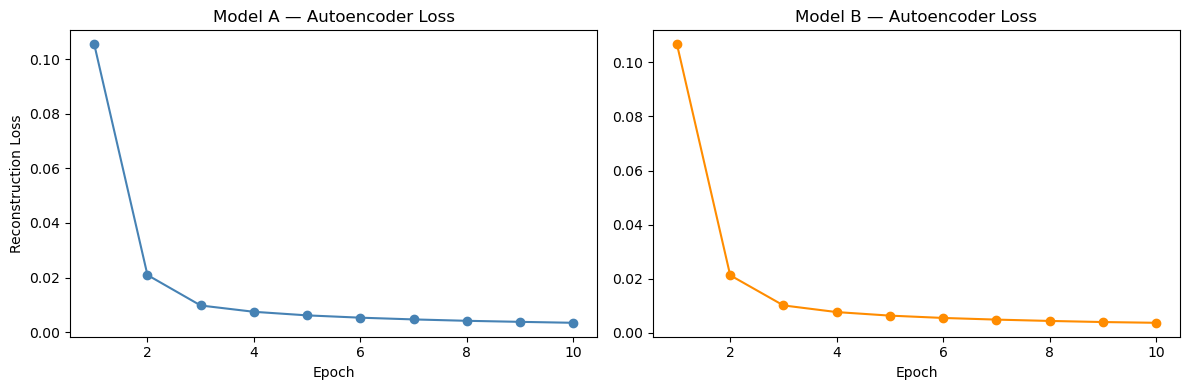


Evaluating 200 test input songs, top-10 recs each...

CROSS-TRAINING EVALUATION RESULTS
Input songs evaluated:    200
Recommendations per song: 10

Mean Jaccard overlap:     0.7043
  1.0 = both models recommend identical songs
  0.0 = no songs in common between models

Mean overlap count (out of 10): 8.16

Mean genre match — Model A: 1.0000
Mean genre match — Model B: 1.0000

Per-genre Jaccard overlap:
genre
other         0.7766
classical     0.7766
rock          0.7333
folk          0.7327
ambient       0.7229
world         0.7218
pop           0.7198
metal         0.7155
jazz          0.6914
electronic    0.6682
latin         0.6667
hip-hop       0.6629


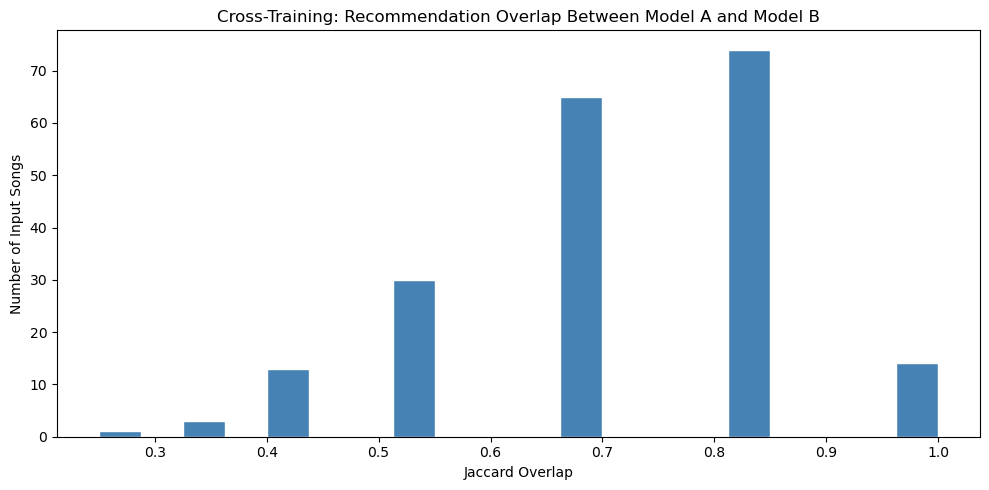

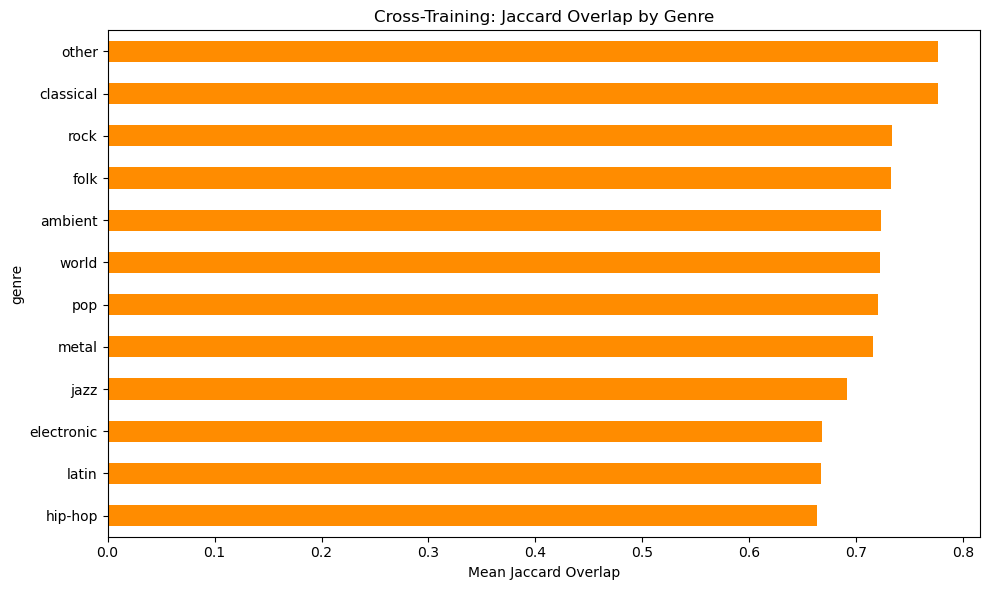

In [22]:
def evaluate_cross_training(df, scaler, le,
                              n_query_songs=200, n=10,
                              alpha=0.65, beta=0.35,
                              train_size_a=0.4, train_size_b=0.4,
                              random_state_a=42, random_state_b=99):
    """
    True cross-training evaluation: trains two independent MLP + Autoencoder pipelines
    on non-overlapping subsets, then measures how many songs appear in both models'
    top-N recommendation lists (Jaccard overlap).

    Memory strategy: numpy memmaps write large arrays directly to disk instead of RAM.
    Embeddings are extracted in chunks of 100k so RAM never holds the full array.
    Each model's intermediate data is deleted and garbage-collected before the next
    model trains, so peak RAM stays low throughout.
    """
    audio_features = [
        'danceability', 'energy', 'loudness', 'speechiness',
        'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo'
    ]

    # get all dataframe indices as numpy array
    all_indices = np.array(df.index.tolist())

    # split off Set A (40%) with stratification
    remaining, train_a_idx = train_test_split(
        all_indices, test_size=train_size_a, random_state=random_state_a,
        stratify=df.loc[all_indices, 'broad_genre']
    )
    # compute fraction of remaining data that Set B should take
    frac_b = min(train_size_b / (1.0 - train_size_a), 0.99)
    # split remaining into Set B and test set
    test_idx, train_b_idx = train_test_split(
        remaining, test_size=frac_b, random_state=random_state_b,
        stratify=df.loc[remaining, 'broad_genre']
    )

    print(f"Set A: {len(train_a_idx):,} | Set B: {len(train_b_idx):,} | Test: {len(test_idx):,}")
    print("Sets A and B have zero overlap — confirmed by design.")

    # number of songs in full dataset
    n_songs = len(df)
    # chunk size for embedding extraction — keeps RAM usage bounded
    CHUNK = 100_000

    # extract full audio matrix once — shared by both models (84MB, acceptable)
    X_audio_full = df[audio_features].values

    def train_full_pipeline(subset_indices, seed, label, latent_save_path):
        """
        Trains one MLP + Autoencoder on a subset, extracts latent vectors for
        ALL songs using disk-backed memmaps to avoid RAM overflow.
        Deletes intermediate data before returning.
        """
        print(f"\n{'='*50}")
        print(f"Training {label}")
        print(f"{'='*50}")

        # get audio features and labels for this training subset
        X_sub = df.loc[subset_indices, audio_features].values
        y_sub = le.transform(df.loc[subset_indices, 'broad_genre'])

        # subsample to 50k for MLP training speed
        n_samp = min(50000, len(X_sub))
        X_samp, y_samp = resample(
            X_sub, y_sub, n_samples=n_samp, random_state=seed, stratify=y_sub
        )
        # free subset arrays — no longer needed after sampling
        del X_sub, y_sub
        gc.collect()

        # train MLP on sampled subset
        mlp_local = MLPClassifier(
            hidden_layer_sizes=(256,), activation='relu',
            learning_rate_init=0.001, max_iter=200,
            early_stopping=True, n_iter_no_change=10,
            random_state=seed, verbose=True
        )
        mlp_local.fit(X_samp, y_samp)
        # free training sample — no longer needed
        del X_samp, y_samp
        gc.collect()
        print(f"{label} MLP training complete.")

        # --- EMBEDDING EXTRACTION via memmap ---
        # write embeddings directly to disk in chunks — never holds full array in RAM
        tmp_emb_path = f'_tmp_emb_{label}.dat'
        # create a disk-backed array of shape (n_songs, 256)
        emb_mm = np.memmap(tmp_emb_path, dtype='float32', mode='w+', shape=(n_songs, 256))

        print(f"Extracting embeddings for all {n_songs:,} songs using {label} (chunked)...")
        for start in range(0, n_songs, CHUNK):
            end = min(start + CHUNK, n_songs)
            # extract embeddings for this chunk and write directly to disk
            emb_mm[start:end] = extract_embeddings(mlp_local, X_audio_full[start:end])
        # flush writes to disk before reading
        emb_mm.flush()

        # free MLP weights — no longer needed after embedding extraction
        del mlp_local
        gc.collect()

        # --- AUTOENCODER TRAINING ---
        # sample 100k embeddings from disk for autoencoder training
        ae_samp_idx = np.random.RandomState(seed).choice(n_songs, min(100000, n_songs), replace=False)
        # read only the sampled rows from disk — ~100MB in RAM
        emb_sample = np.array(emb_mm[ae_samp_idx], dtype='float32')

        # train autoencoder on sampled embeddings
        ae_local = SongAutoencoder(input_dim=256, latent_dim=64)
        tensor = torch.FloatTensor(emb_sample)
        dataset = TensorDataset(tensor)
        loader = DataLoader(dataset, batch_size=2048, shuffle=True)
        criterion_ae = nn.MSELoss()
        optimizer_ae = optim.Adam(ae_local.parameters(), lr=0.001)

        # free sample array after converting to tensor
        del emb_sample
        gc.collect()

        ae_losses = []
        for epoch in range(10):
            total = 0
            for batch in loader:
                x = batch[0]
                optimizer_ae.zero_grad()
                recon, _ = ae_local(x)
                loss = criterion_ae(recon, x)
                loss.backward()
                optimizer_ae.step()
                total += loss.item()
            avg = total / len(loader)
            ae_losses.append(avg)
            print(f"  {label} AE Epoch {epoch+1}/10 — Loss: {avg:.6f}")

        ae_local.eval()

        # --- LATENT VECTOR EXTRACTION via memmap ---
        # write latent vectors directly to disk in chunks
        latent_mm = np.memmap(latent_save_path, dtype='float32', mode='w+', shape=(n_songs, 64))

        print(f"Extracting latent vectors for all {n_songs:,} songs using {label} (chunked)...")
        with torch.no_grad():
            for start in range(0, n_songs, CHUNK):
                end = min(start + CHUNK, n_songs)
                # read embedding chunk from disk, pass through encoder, write latent to disk
                chunk_emb = torch.FloatTensor(np.array(emb_mm[start:end]))
                latent_mm[start:end] = ae_local.encoder(chunk_emb).numpy()
        latent_mm.flush()

        # free autoencoder weights — no longer needed
        del ae_local, chunk_emb
        gc.collect()

        # delete temporary embedding memmap file from disk
        del emb_mm
        try:
            os.remove(tmp_emb_path)
        except Exception:
            pass
        gc.collect()

        print(f"{label} complete. Latent vectors saved to disk: {latent_save_path}")
        # return the disk-backed latent array and loss history
        return latent_mm, ae_losses

    # train Model A — latent vectors written to disk
    latent_a, losses_a = train_full_pipeline(train_a_idx, 42, 'Model A', '_latent_a.dat')
    # force full garbage collection before training Model B
    gc.collect()

    # train Model B — latent vectors written to disk
    latent_b, losses_b = train_full_pipeline(train_b_idx, 99, 'Model B', '_latent_b.dat')
    gc.collect()

    # plot autoencoder training curves for both models
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(range(1, 11), losses_a, marker='o', color='steelblue')
    axes[0].set_title('Model A — Autoencoder Loss')
    axes[0].set_xlabel('Epoch')
    axes[0].set_ylabel('Reconstruction Loss')
    axes[1].plot(range(1, 11), losses_b, marker='o', color='darkorange')
    axes[1].set_title('Model B — Autoencoder Loss')
    axes[1].set_xlabel('Epoch')
    plt.tight_layout()
    plt.show()

    # sample test songs to evaluate
    n_query = min(n_query_songs, len(test_idx))
    rng = np.random.default_rng(42)
    eval_positions = rng.choice(len(test_idx), size=n_query, replace=False)

    print(f"\nEvaluating {n_query} test input songs, top-{n} recs each...")

    results = []

    for pos in eval_positions:
        # get the original dataframe index for this test song
        song_idx = test_idx[pos]
        song_row = df.loc[song_idx]
        original_genre = song_row['original_genre']

        # read this song's latent vectors from disk (minimal RAM — single row)
        q_lat_a = np.array(latent_a[song_idx], dtype='float32').reshape(1, -1)
        q_lat_b = np.array(latent_b[song_idx], dtype='float32').reshape(1, -1)
        q_aud   = X_audio_full[song_idx].reshape(1, -1)

        # get all candidate indices sharing the same original genre
        same_genre_mask = (df['original_genre'] == original_genre).values
        same_genre_indices = np.where(same_genre_mask)[0].tolist()

        if len(same_genre_indices) < n + 1:
            continue

        # read latent vectors for candidates from disk in one shot
        # memmap reads only the requested rows — efficient
        cand_latent_a = np.array(latent_a[same_genre_indices], dtype='float32')
        cand_latent_b = np.array(latent_b[same_genre_indices], dtype='float32')
        cand_audio    = X_audio_full[same_genre_indices]

        # compute combined scores for Model A candidates
        score_a = (
            alpha * cosine_similarity(q_lat_a, cand_latent_a)[0] +
            beta  * cosine_similarity(q_aud,   cand_audio)[0]
        )
        top_a_pos = [p for p in np.argsort(score_a)[::-1] if same_genre_indices[p] != song_idx][:n]
        top_a_idx = [same_genre_indices[p] for p in top_a_pos]

        # compute combined scores for Model B candidates
        score_b = (
            alpha * cosine_similarity(q_lat_b, cand_latent_b)[0] +
            beta  * cosine_similarity(q_aud,   cand_audio)[0]
        )
        top_b_pos = [p for p in np.argsort(score_b)[::-1] if same_genre_indices[p] != song_idx][:n]
        top_b_idx = [same_genre_indices[p] for p in top_b_pos]

        # free candidate arrays for this iteration
        del cand_latent_a, cand_latent_b, cand_audio

        # compare top-N lists using track IDs
        recs_a = set(df.iloc[top_a_idx]['track_id'].values)
        recs_b = set(df.iloc[top_b_idx]['track_id'].values)

        # jaccard similarity: shared songs / all unique songs across both lists
        intersection = len(recs_a & recs_b)
        union = len(recs_a | recs_b)
        jaccard = intersection / union if union > 0 else 0.0

        match_a = (df.iloc[top_a_idx]['original_genre'] == original_genre).mean()
        match_b = (df.iloc[top_b_idx]['original_genre'] == original_genre).mean()

        results.append({
            'song':           song_row['track_name'],
            'artist':         song_row['artist_name'],
            'genre':          song_row['broad_genre'],
            'original_genre': original_genre,
            'overlap_count':  intersection,
            'jaccard':        round(jaccard, 4),
            'genre_match_a':  round(match_a, 4),
            'genre_match_b':  round(match_b, 4),
        })

    results_df = pd.DataFrame(results)

    # print summary statistics
    print("\n" + "=" * 55)
    print("CROSS-TRAINING EVALUATION RESULTS")
    print("=" * 55)
    print(f"Input songs evaluated:    {len(results_df)}")
    print(f"Recommendations per song: {n}")
    print()
    print(f"Mean Jaccard overlap:     {results_df['jaccard'].mean():.4f}")
    print(f"  1.0 = both models recommend identical songs")
    print(f"  0.0 = no songs in common between models")
    print()
    print(f"Mean overlap count (out of {n}): {results_df['overlap_count'].mean():.2f}")
    print()
    print(f"Mean genre match — Model A: {results_df['genre_match_a'].mean():.4f}")
    print(f"Mean genre match — Model B: {results_df['genre_match_b'].mean():.4f}")
    print()
    print("Per-genre Jaccard overlap:")
    print(
        results_df.groupby('genre')['jaccard']
        .mean().sort_values(ascending=False)
        .map('{:.4f}'.format).to_string()
    )
    print("=" * 55)

    # plot jaccard distribution
    plt.figure(figsize=(10, 5))
    plt.hist(results_df['jaccard'], bins=20, color='steelblue', edgecolor='white')
    plt.xlabel('Jaccard Overlap')
    plt.ylabel('Number of Input Songs')
    plt.title('Cross-Training: Recommendation Overlap Between Model A and Model B')
    plt.tight_layout()
    plt.show()

    # plot per-genre jaccard
    plt.figure(figsize=(10, 6))
    results_df.groupby('genre')['jaccard'].mean().sort_values().plot(
        kind='barh', color='darkorange'
    )
    plt.xlabel('Mean Jaccard Overlap')
    plt.title('Cross-Training: Jaccard Overlap by Genre')
    plt.tight_layout()
    plt.show()

    # clean up disk-backed memmap files
    del latent_a, latent_b
    try:
        os.remove('_latent_a.dat')
        os.remove('_latent_b.dat')
    except Exception:
        pass
    gc.collect()

    return results_df

cross_eval_results = evaluate_cross_training(df, scaler, le, n_query_songs=200, n=10)

In [23]:
# save both evaluation results to disk
eval_results.to_csv('eval_baseline_results.csv', index=False)
print("Baseline eval results saved.")

cross_eval_results.to_csv('eval_cross_training_results.csv', index=False)
print("Cross-training eval results saved.")

Baseline eval results saved.
Cross-training eval results saved.


In [24]:
# load saved evaluation results
eval_results = pd.read_csv('eval_baseline_results.csv')
cross_eval_results = pd.read_csv('eval_cross_training_results.csv')

print("Eval results loaded.")
print(f"Baseline: {len(eval_results)} rows")
print(f"Cross-training: {len(cross_eval_results)} rows")

Eval results loaded.
Baseline: 200 rows
Cross-training: 200 rows
